# LEGEND poster · 3/3 — publication-style figures (plot only)

The 5 figures load the **saved, checksum-verified** WIMP-LEGEND spectra and 27-scenario SI limit table. They do **not** run detector folding or statistical inference.

Sensitivity figures use the **same DirectDetectionPlots datasets and `PlotBound` shaded regions, inline labels, and dashed SuperCDMS/CDEX projections** as `DM-Nucleon_LEGEND(1).ipynb` (LZ 2026, XENONnT 2026, PandaX 2025, Xe neutrino fog). Configure the location of your separate DirectDetectionPlots checkout below. No silent substitution of older limits is allowed.


In [5]:
from pathlib import Path
import sys

def find_repo_root():
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / 'pyproject.toml').is_file() and (candidate / 'analyses/legend_poster').is_dir():
            return candidate
    raise RuntimeError('Open this notebook in the WIMP-LEGEND checkout (or a subdirectory).')

ROOT = find_repo_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
# CAMPAIGN_DIR = ROOT / 'analyses/legend_poster/campaigns/poster_final'
CAMPAIGN_DIR = ROOT / 'analyses/legend_poster/campaigns/poster_sigma20'
SPEC_PATH = ROOT / 'analyses/legend_poster/poster_campaign_spec.json'
CONFIG_PATH = CAMPAIGN_DIR / 'config.json'
print('Repository:', ROOT)
print('Campaign:', CAMPAIGN_DIR)


Repository: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code
Campaign: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\poster_sigma20


## Load and verify the completed numerical campaign

In [6]:
import json
from analyses.legend_poster.campaign_scripts.poster_campaign import load_campaign, load_spec

source_index = json.loads((CAMPAIGN_DIR/'source_run.json').read_text())
RUN_DIR = ROOT/source_index['run_relative']
rows, manifest = load_campaign(CAMPAIGN_DIR)
spec = load_spec(SPEC_PATH)
assert manifest['source_run_id'] == source_index['run_id']
print('Verified limit table:',len(rows),'rows')
print('Source run:',RUN_DIR)
print('Three backgrounds:', manifest['background_modes'])
print('Thresholds [keVee]:',manifest['threshold_keVee'])
print('Exposures [t·yr]:',manifest['exposure_tonne_year'])


Verified limit table: 2133 rows
Source run: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\poster_sigma20\runs\ed8ac71f232a961dc2f3
Three backgrounds: ['none', 'neutrinos', 'full']
Thresholds [keVee]: [0.1, 0.15, 1.0]
Exposures [t·yr]: [0.1, 1.0, 10.0]


## Plot settings — edit and rerun freely

Set `DDP_ROOT` to the checkout containing `notebooks/PlotFuncs.py` and `data/limits/Nucleon/SI/`. Leave it as `None` to autodetect from `DIRECT_DETECTION_PLOTS_ROOT` or a sibling folder. If unavailable, change `COMPARISON_MODE` explicitly to `"frozen"` (older WIMP-LEGEND snapshots) or `"none"`.

Figures 2–5 default to the **1–10 GeV, 10⁻⁴⁶–10⁻⁴² cm²** viewport used in the supplied notebook. Increase the ranges below to show higher-mass WIMPs. `PlotBound` is imported directly from your checkout; the figures are saved locally under this campaign rather than in DirectDetectionPlots/plots.

Figure 1 shows **bin-averaged detector-folded spectra**, and combines all EC lines in one curve to reduce crowding. Physics outputs and numerical interpolation are unchanged.


In [7]:
import os
from pathlib import Path
from analyses.legend_poster.campaign_scripts.poster_figures import plot_five, locate_ddp

# Example for an explicit checkout elsewhere on Windows:
# DDP_ROOT = Path(r'C:\Users\Tiago\...\DirectDetectionPlots')
DDP_ROOT = None
COMPARISON_MODE = 'ddp'  # 'ddp' (exact uploaded notebook), 'frozen', or 'none'

# Match DM-Nucleon_LEGEND(1).ipynb for the low-mass poster panels.
MASS_XLIM = (1., 10.)
SI_YLIM = (1e-49, 1e-42)  # wider than reference: include 10 t·yr best-case curves
FIGURE_DPI = 220
FIGURE_SIZE = (11.5, 7.5)
AXIS_LABEL_SIZE = 28     # x and y label fonts
TICK_LABEL_SIZE = 17
EXPERIMENT_LABEL_SIZE = 16
LEGEND_FONT_SIZE = 13
SHOW_FOG = True
SHOW_TITLES = False
FIGURE_DIR = CAMPAIGN_DIR / 'figures'

if COMPARISON_MODE == 'ddp':
    print('DirectDetectionPlots:', locate_ddp(ROOT, DDP_ROOT))

paths = plot_five(
    CAMPAIGN_DIR, RUN_DIR, SPEC_PATH, ROOT,
    ddp_root=DDP_ROOT, comparison_mode=COMPARISON_MODE,
    xlim=MASS_XLIM, ylim=SI_YLIM, dpi=FIGURE_DPI,
    figure_size=FIGURE_SIZE, label_size=AXIS_LABEL_SIZE,
    tick_size=TICK_LABEL_SIZE, annotation_size=EXPERIMENT_LABEL_SIZE,
    legend_size=LEGEND_FONT_SIZE, show_fog=SHOW_FOG,
    show_titles=SHOW_TITLES, figure_dir=FIGURE_DIR,
)
print('Figures saved to:', paths)
for p in sorted(paths.glob('*.pdf')):
    print(' -', p.name)


DirectDetectionPlots: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\notebooks\DirectDetectionPlots
Figures saved to: C:\Users\Tiago\Desktop\Tiago\Studium\HiWi\MPIK\LEGEND\DM Spektra\WIMP Code\analyses\legend_poster\campaigns\poster_sigma20\figures
 - 01_energy_spectra.pdf
 - 02_neutrino_best_case.pdf
 - 03_background_comparison.pdf
 - 04_threshold_comparison.pdf
 - 05_exposure_comparison.pdf


## Preview figures without recalculation

01_energy_spectra


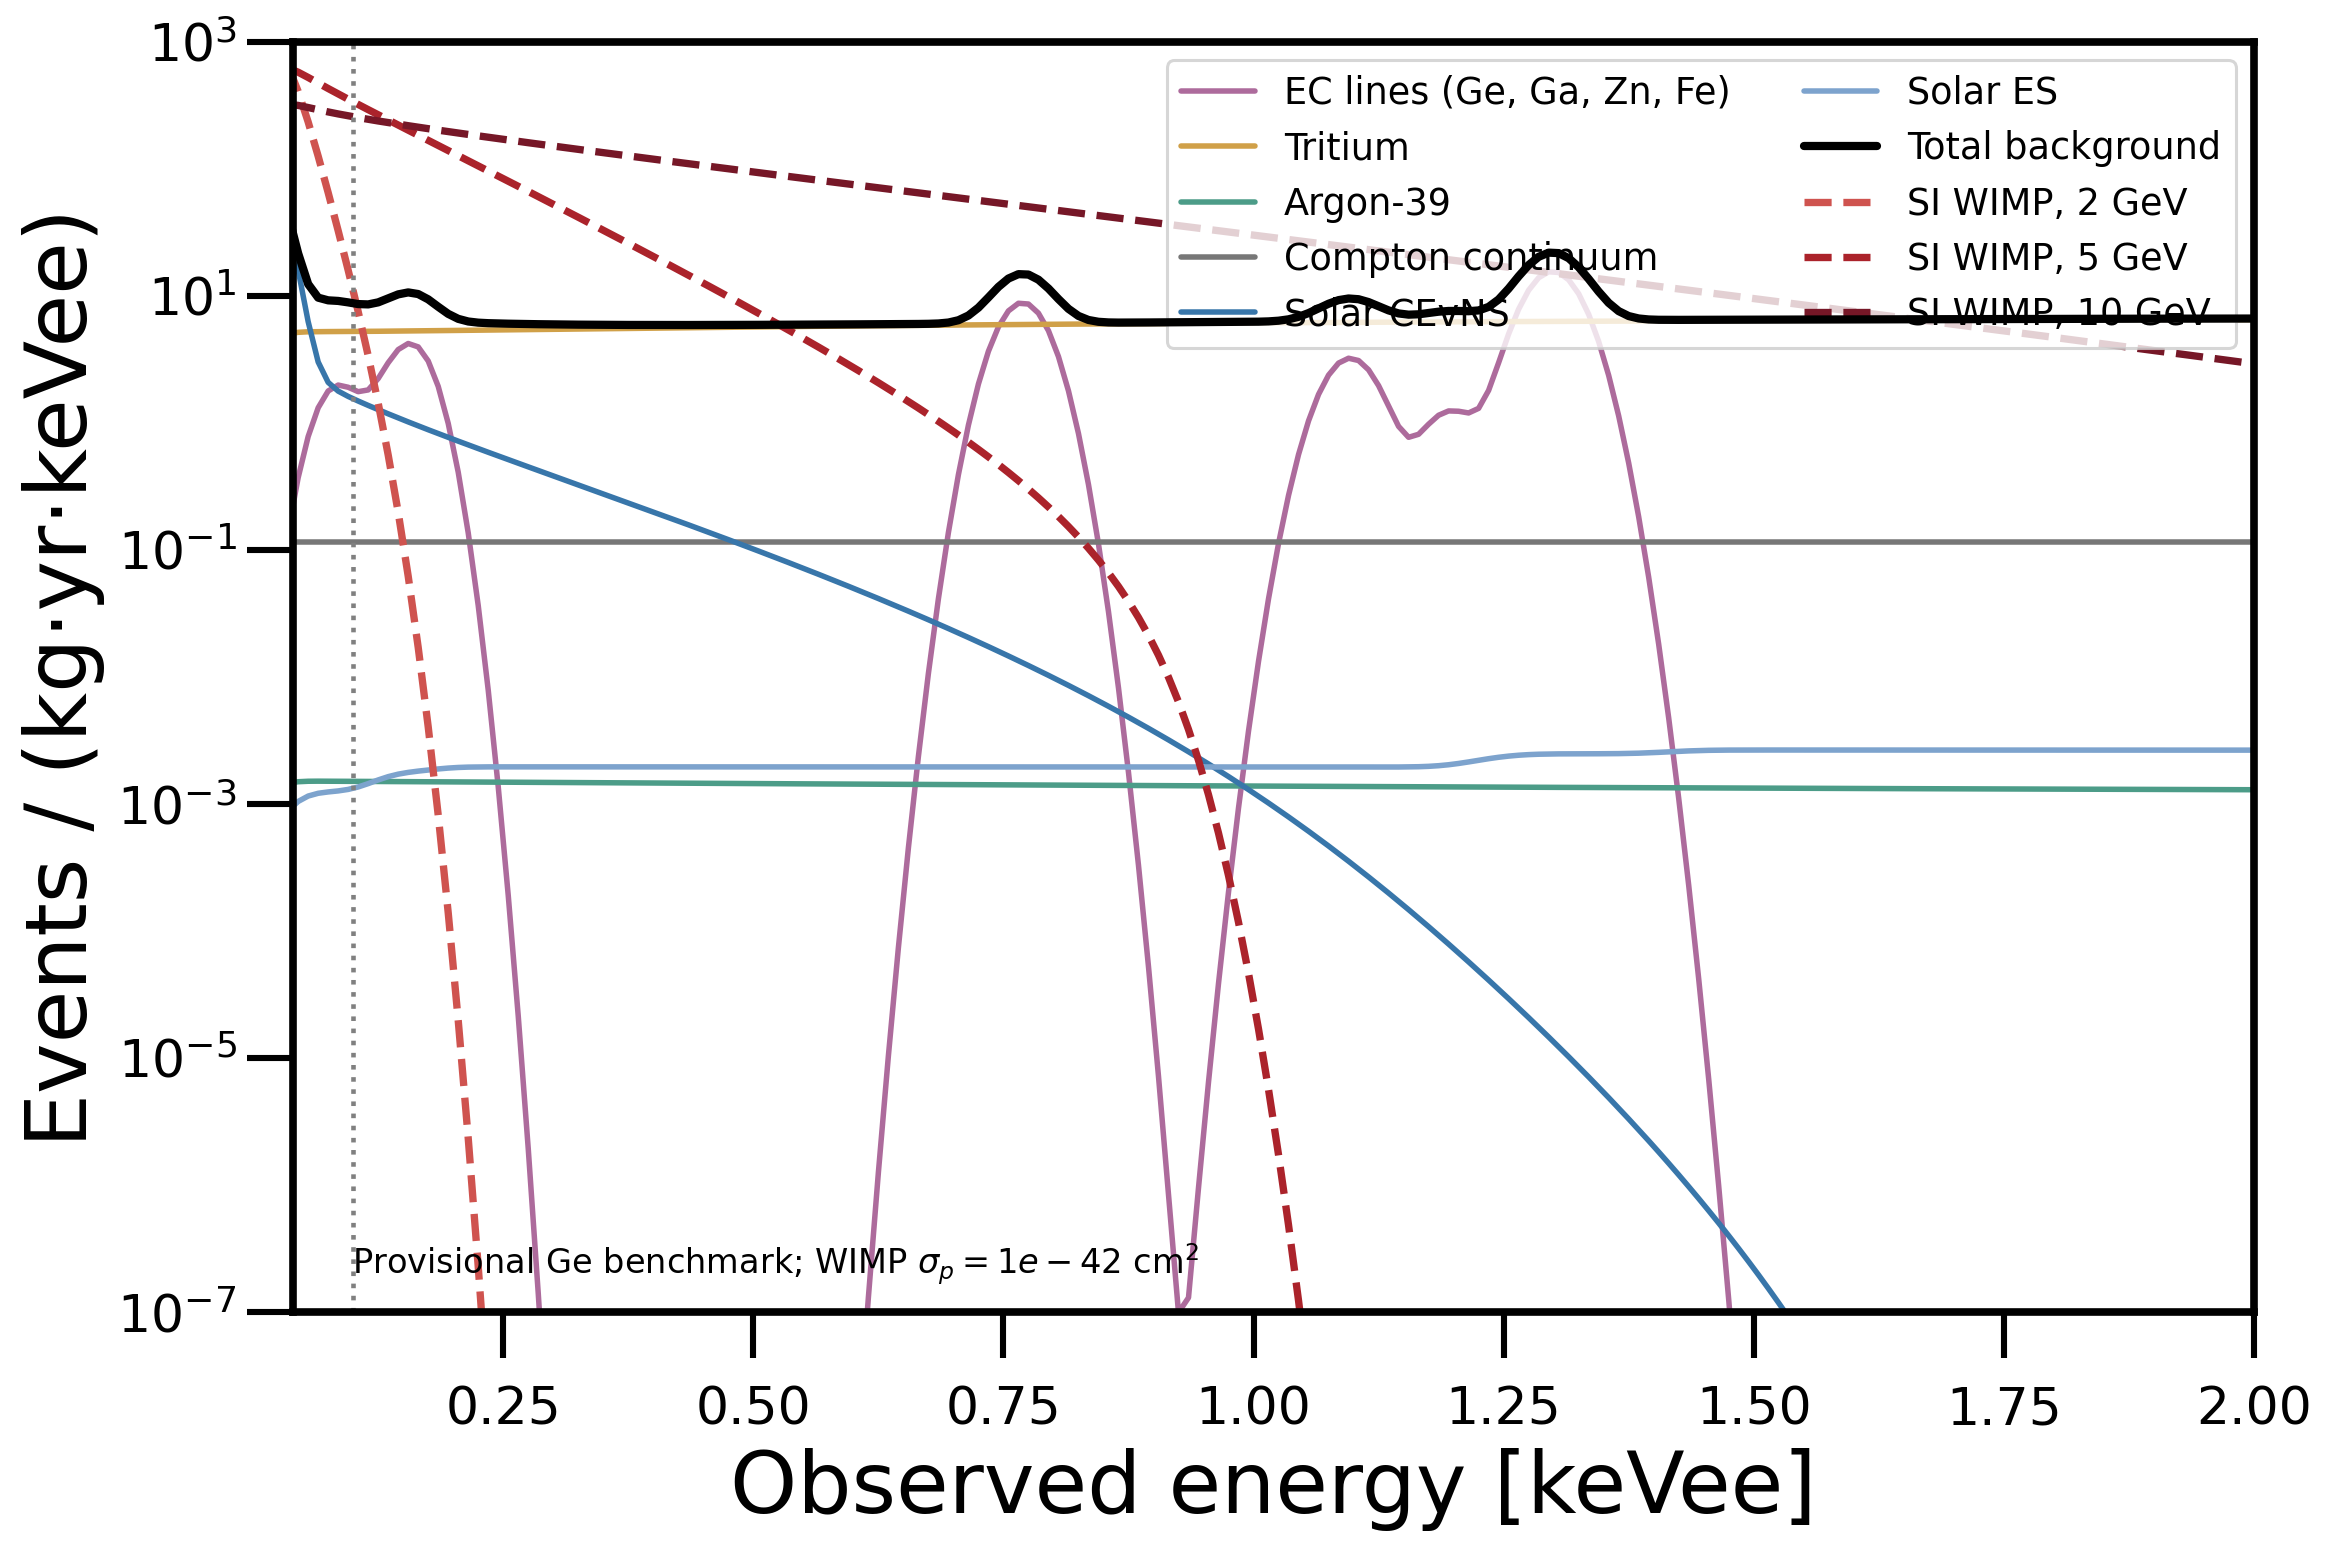

02_neutrino_best_case


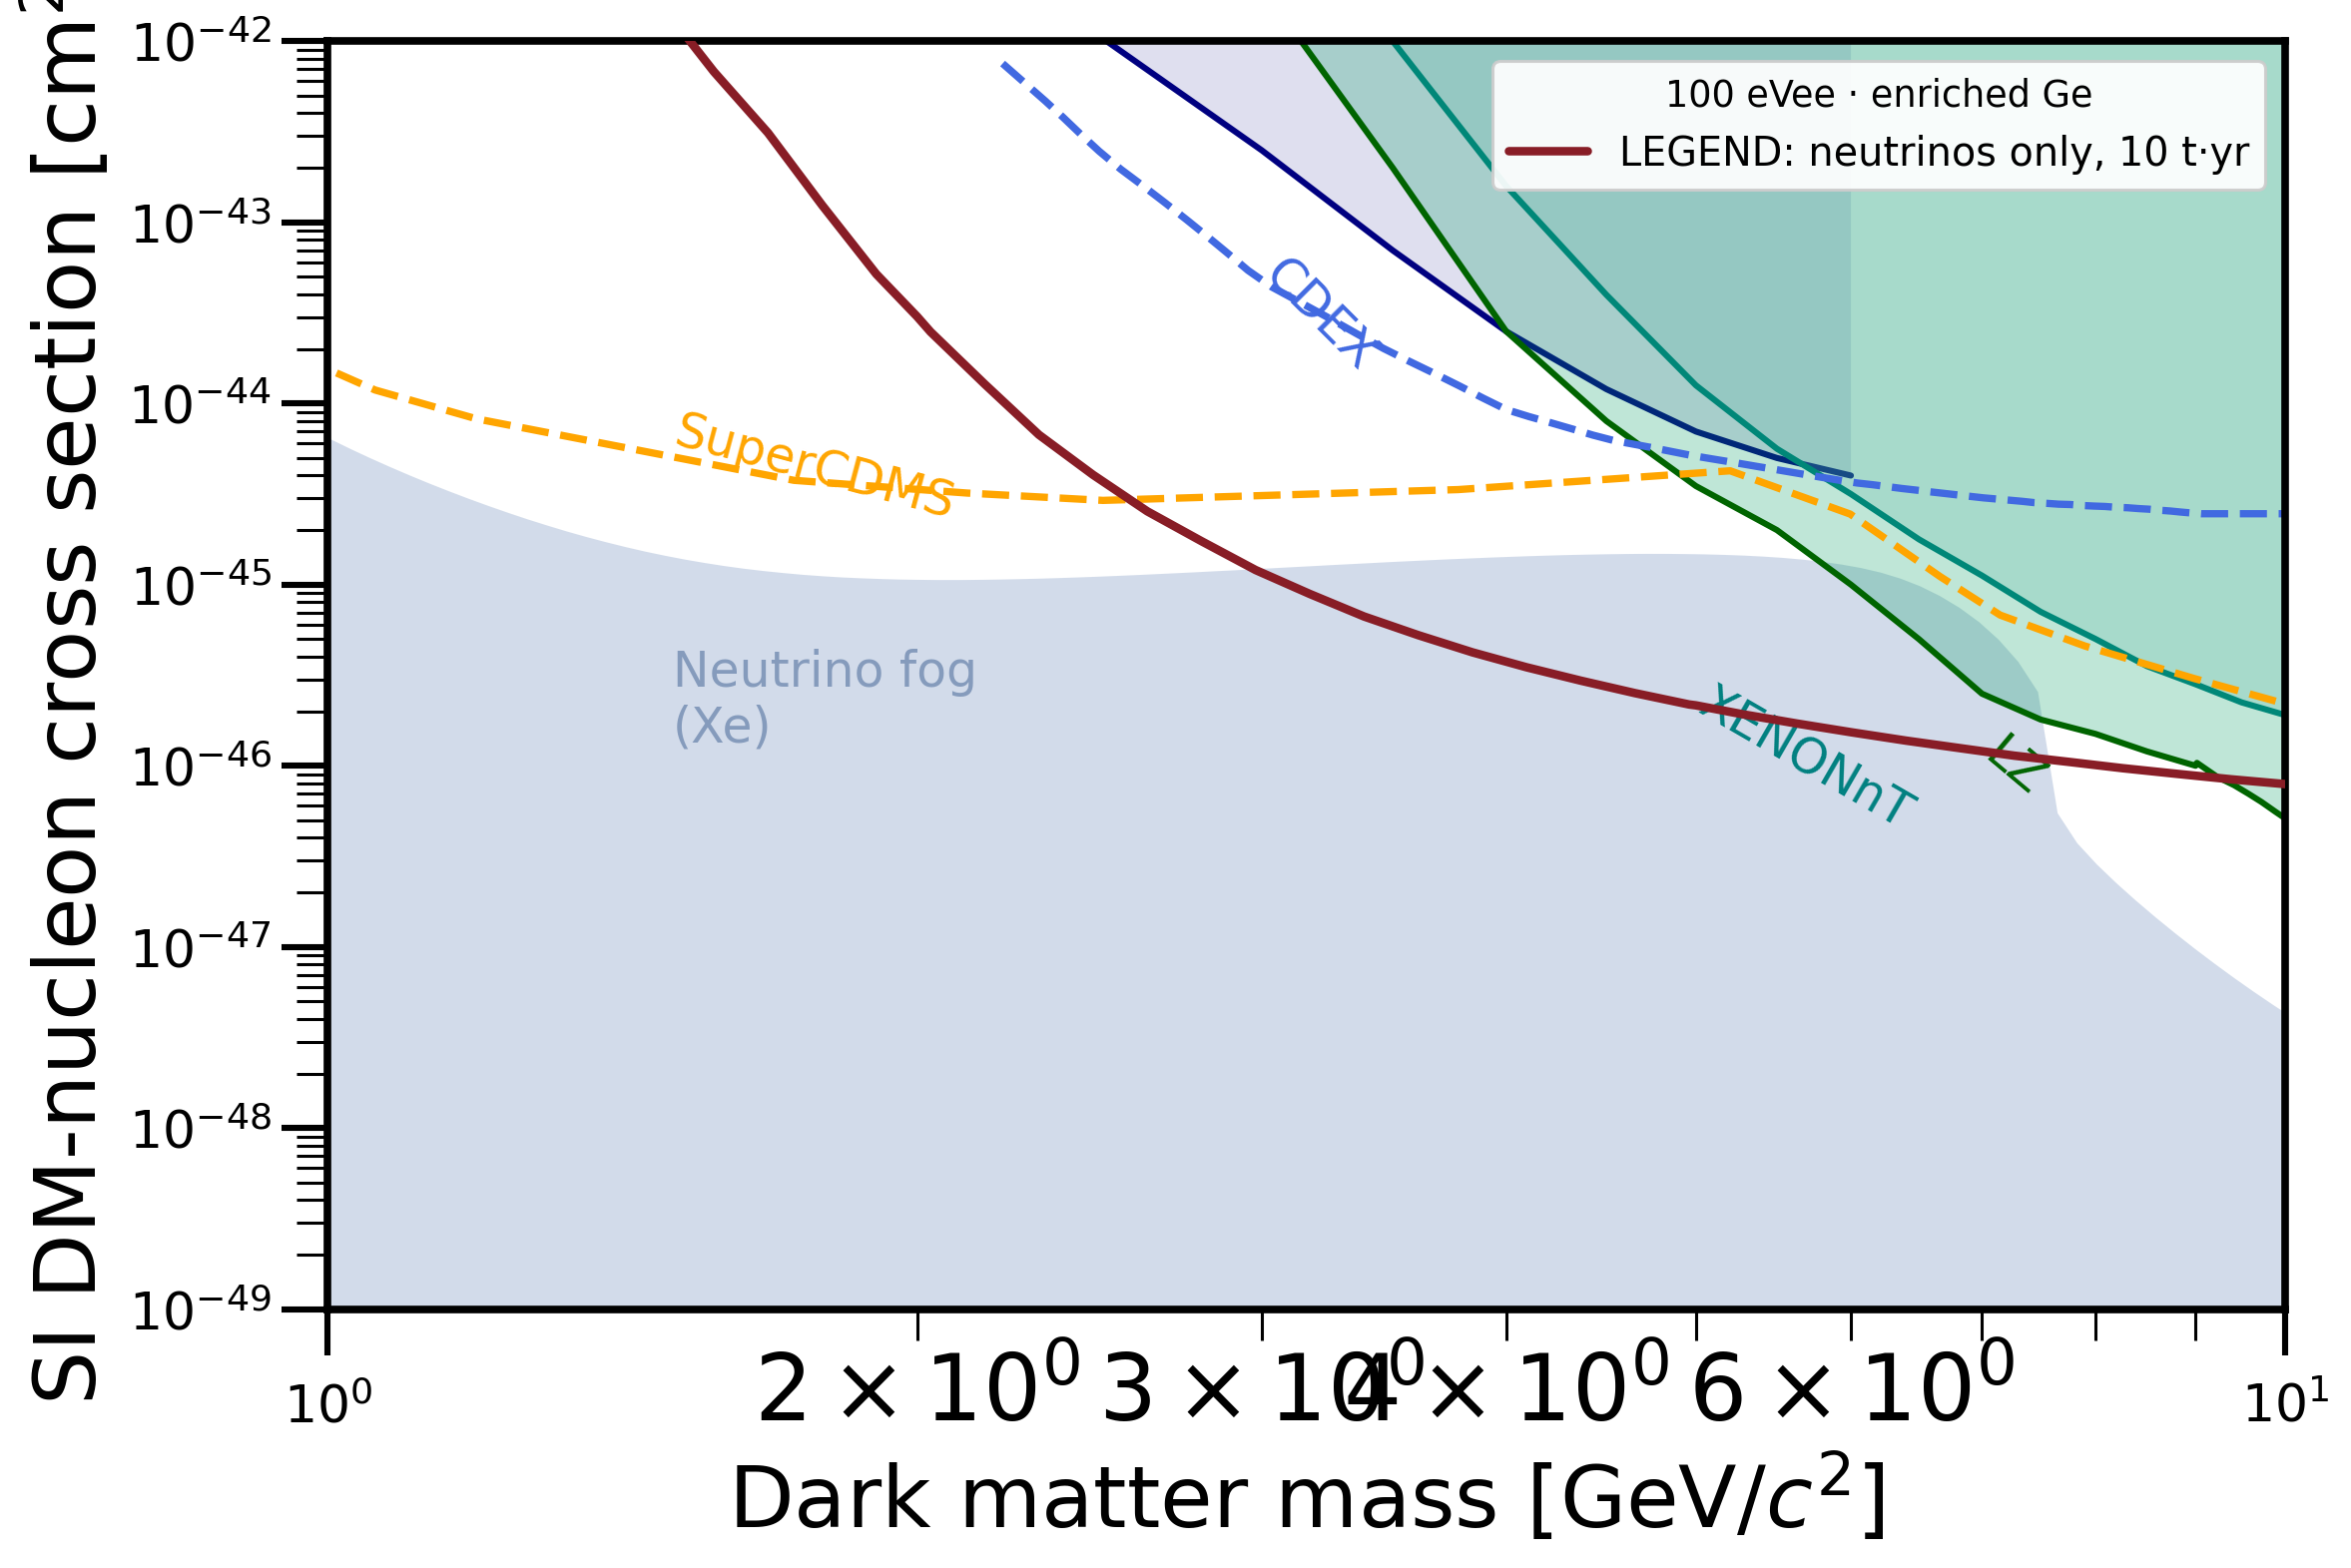

03_background_comparison


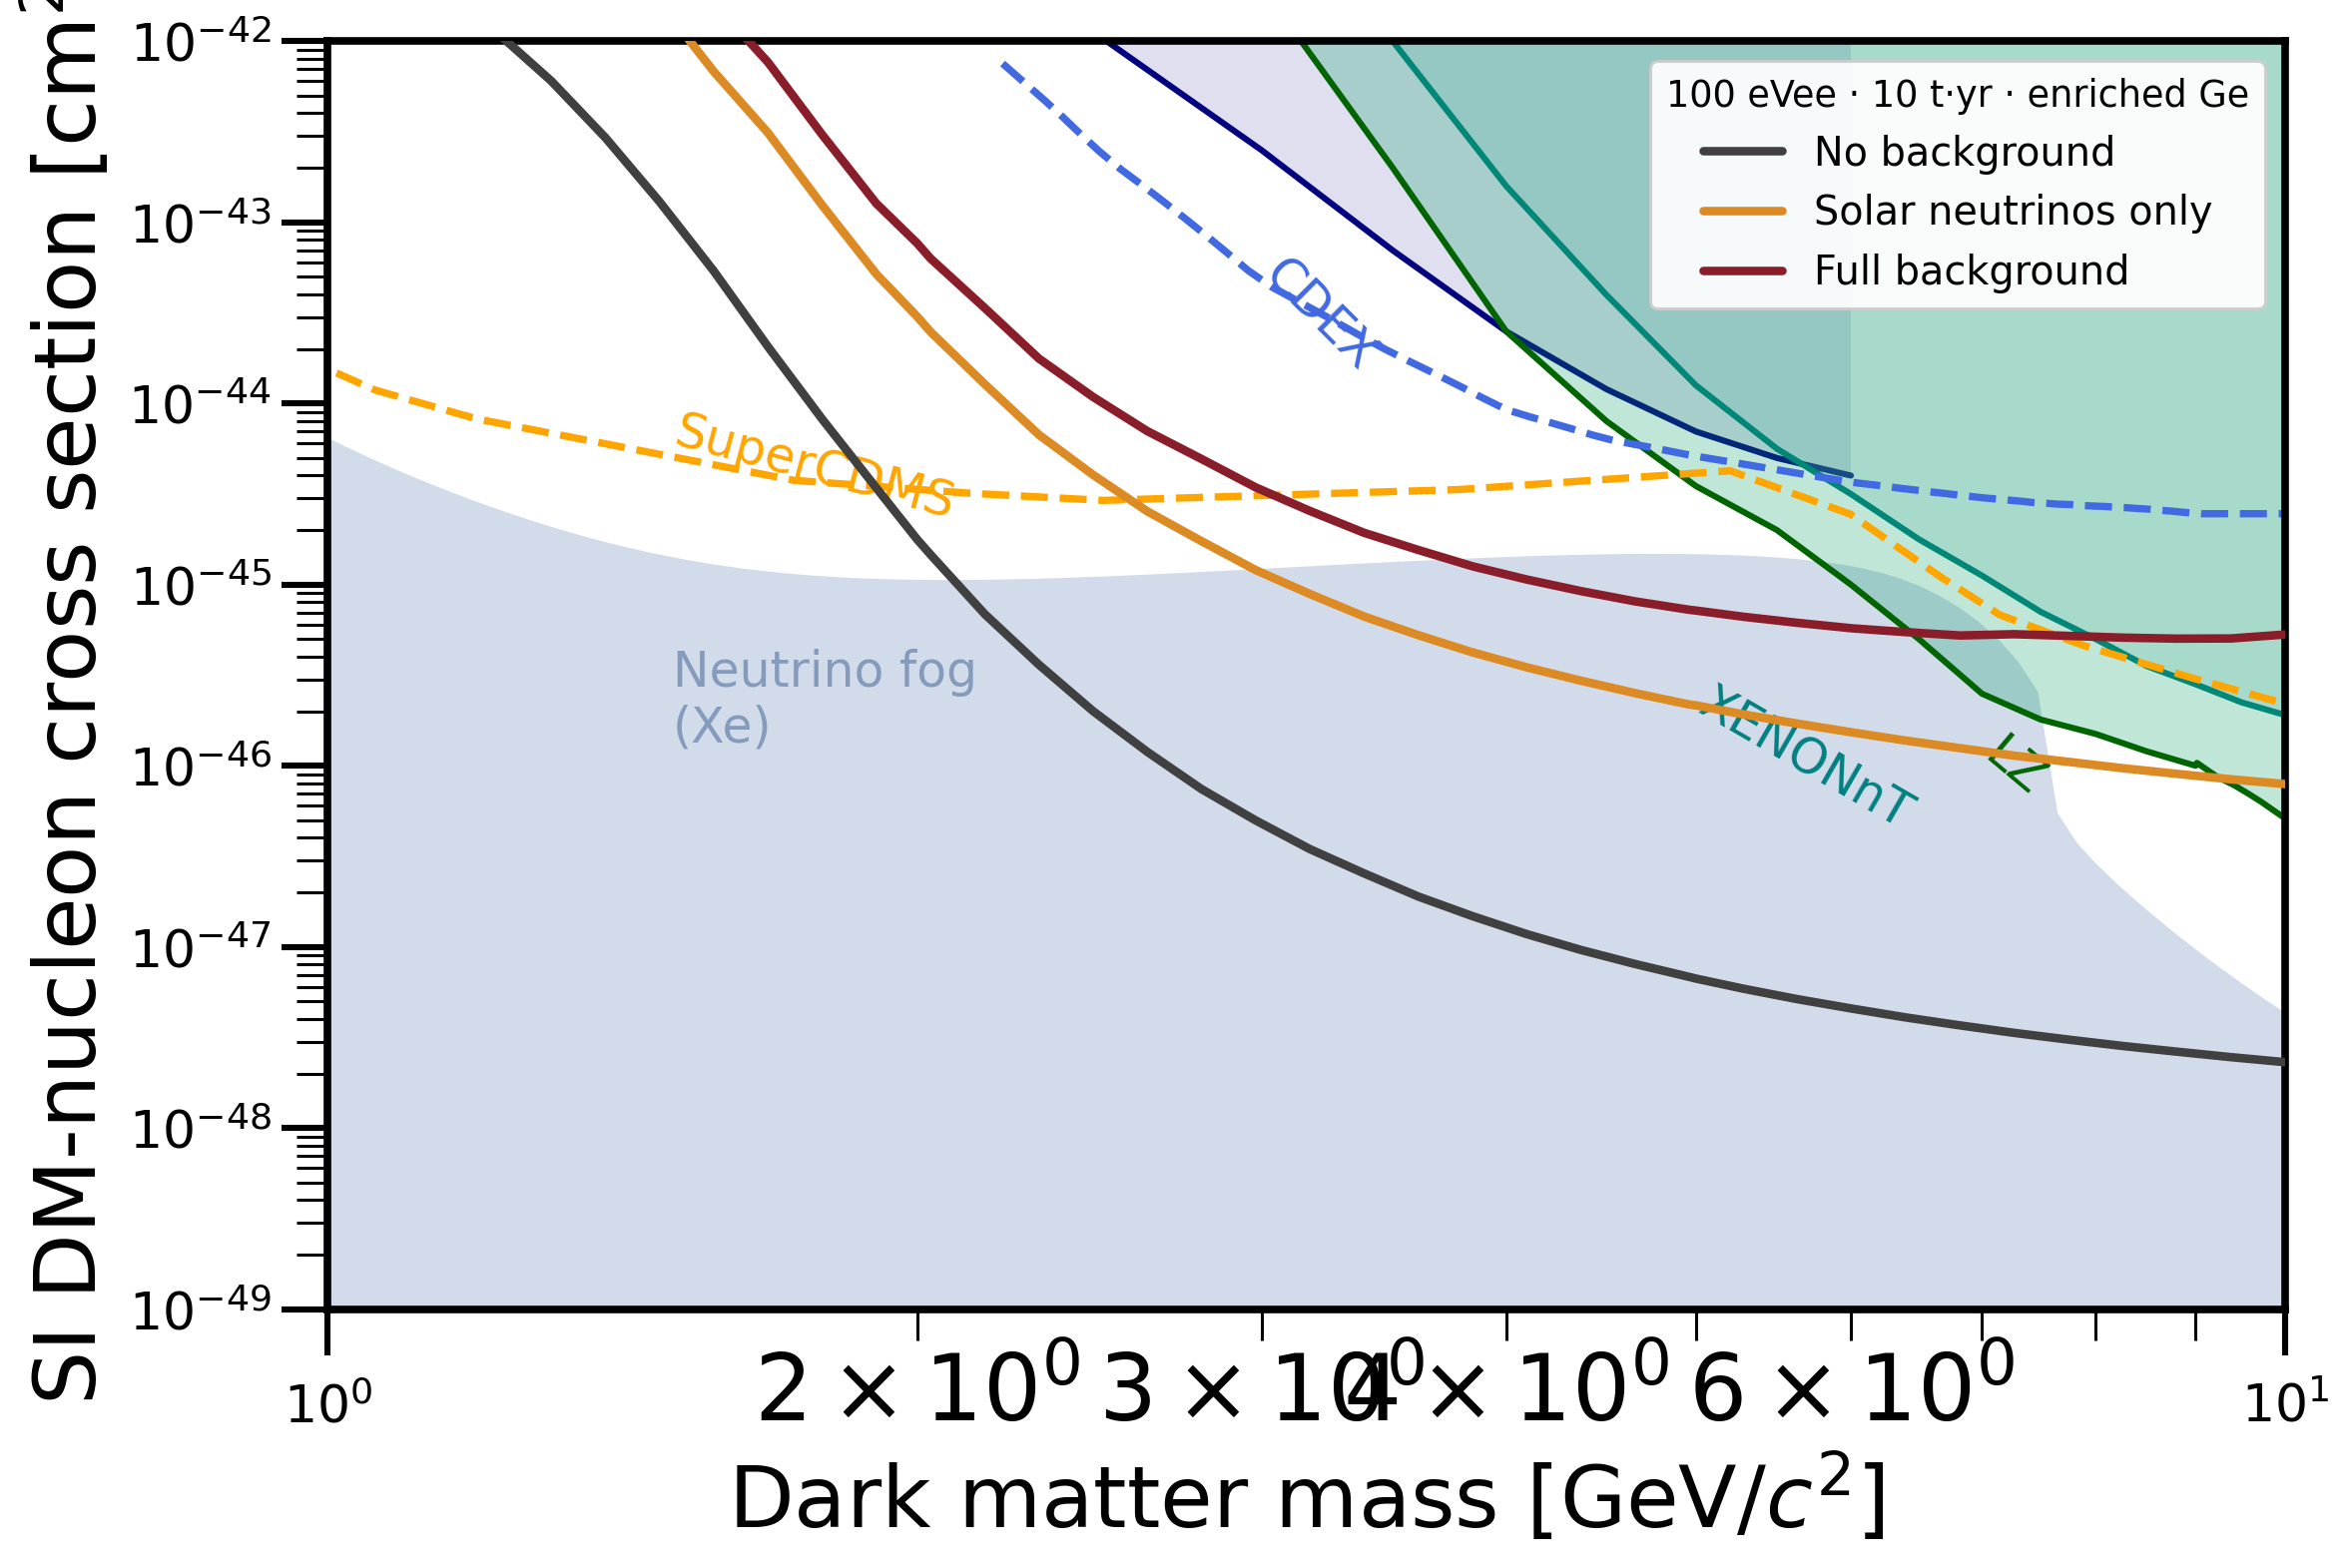

04_threshold_comparison


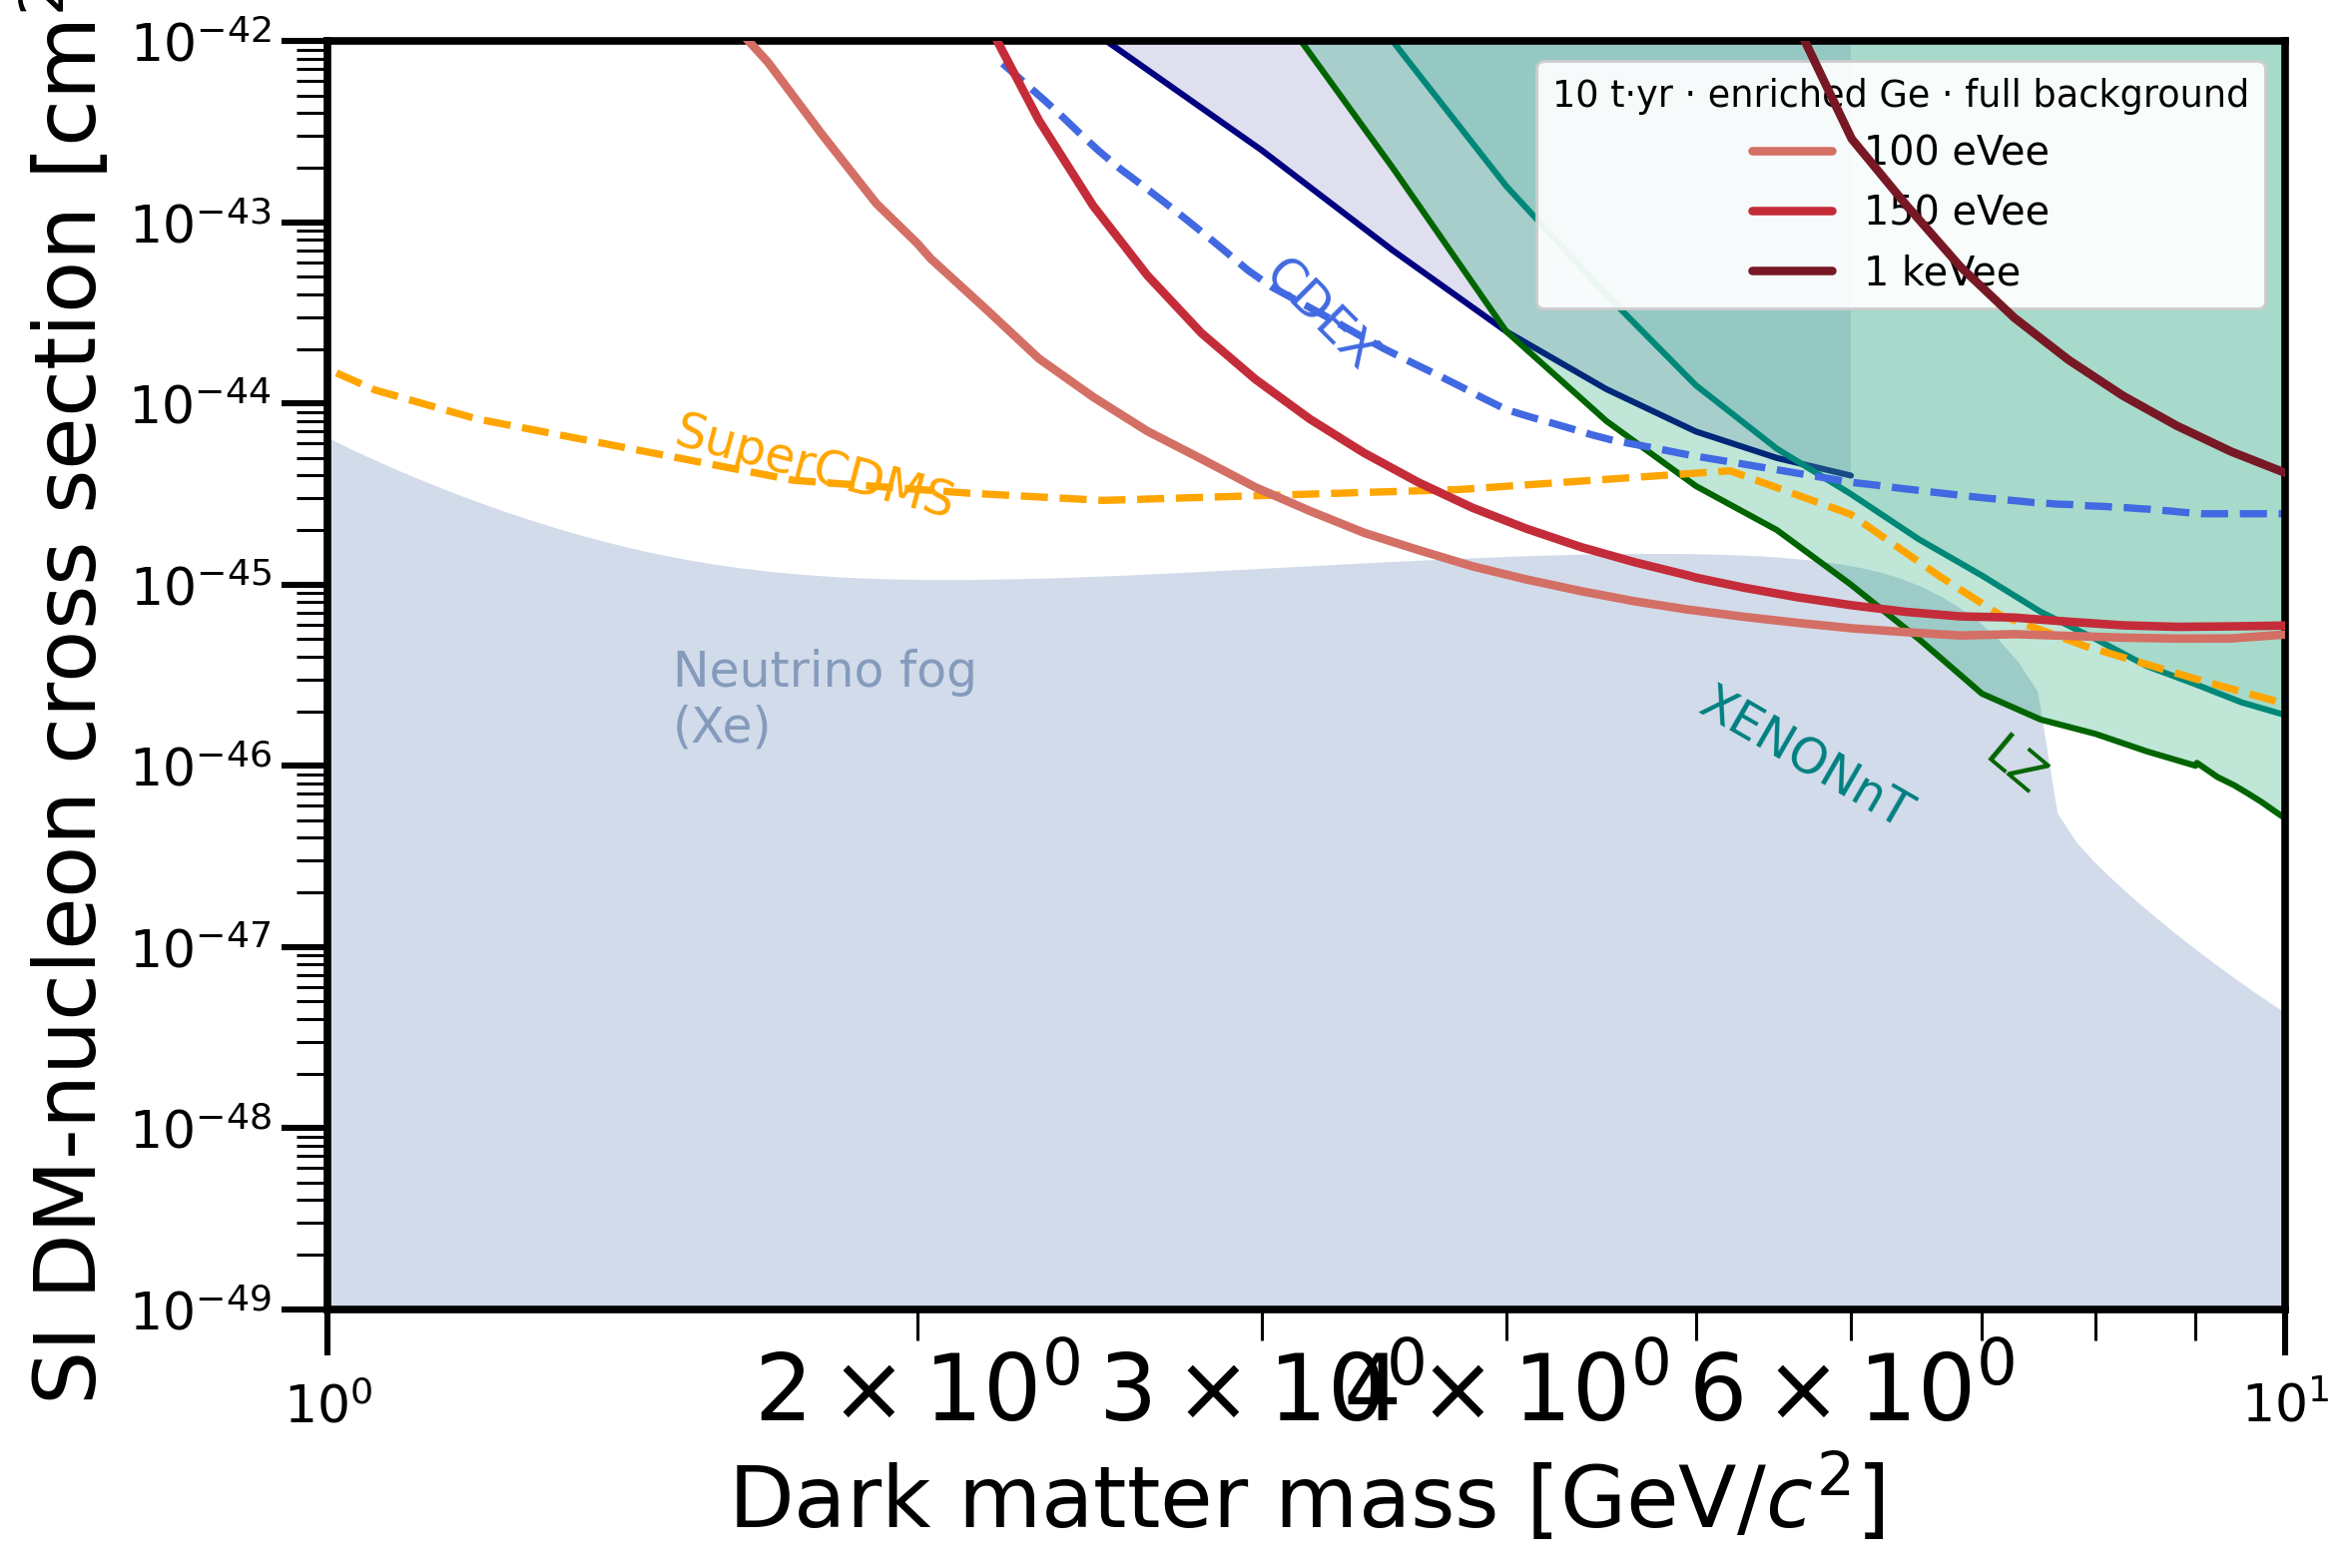

05_exposure_comparison


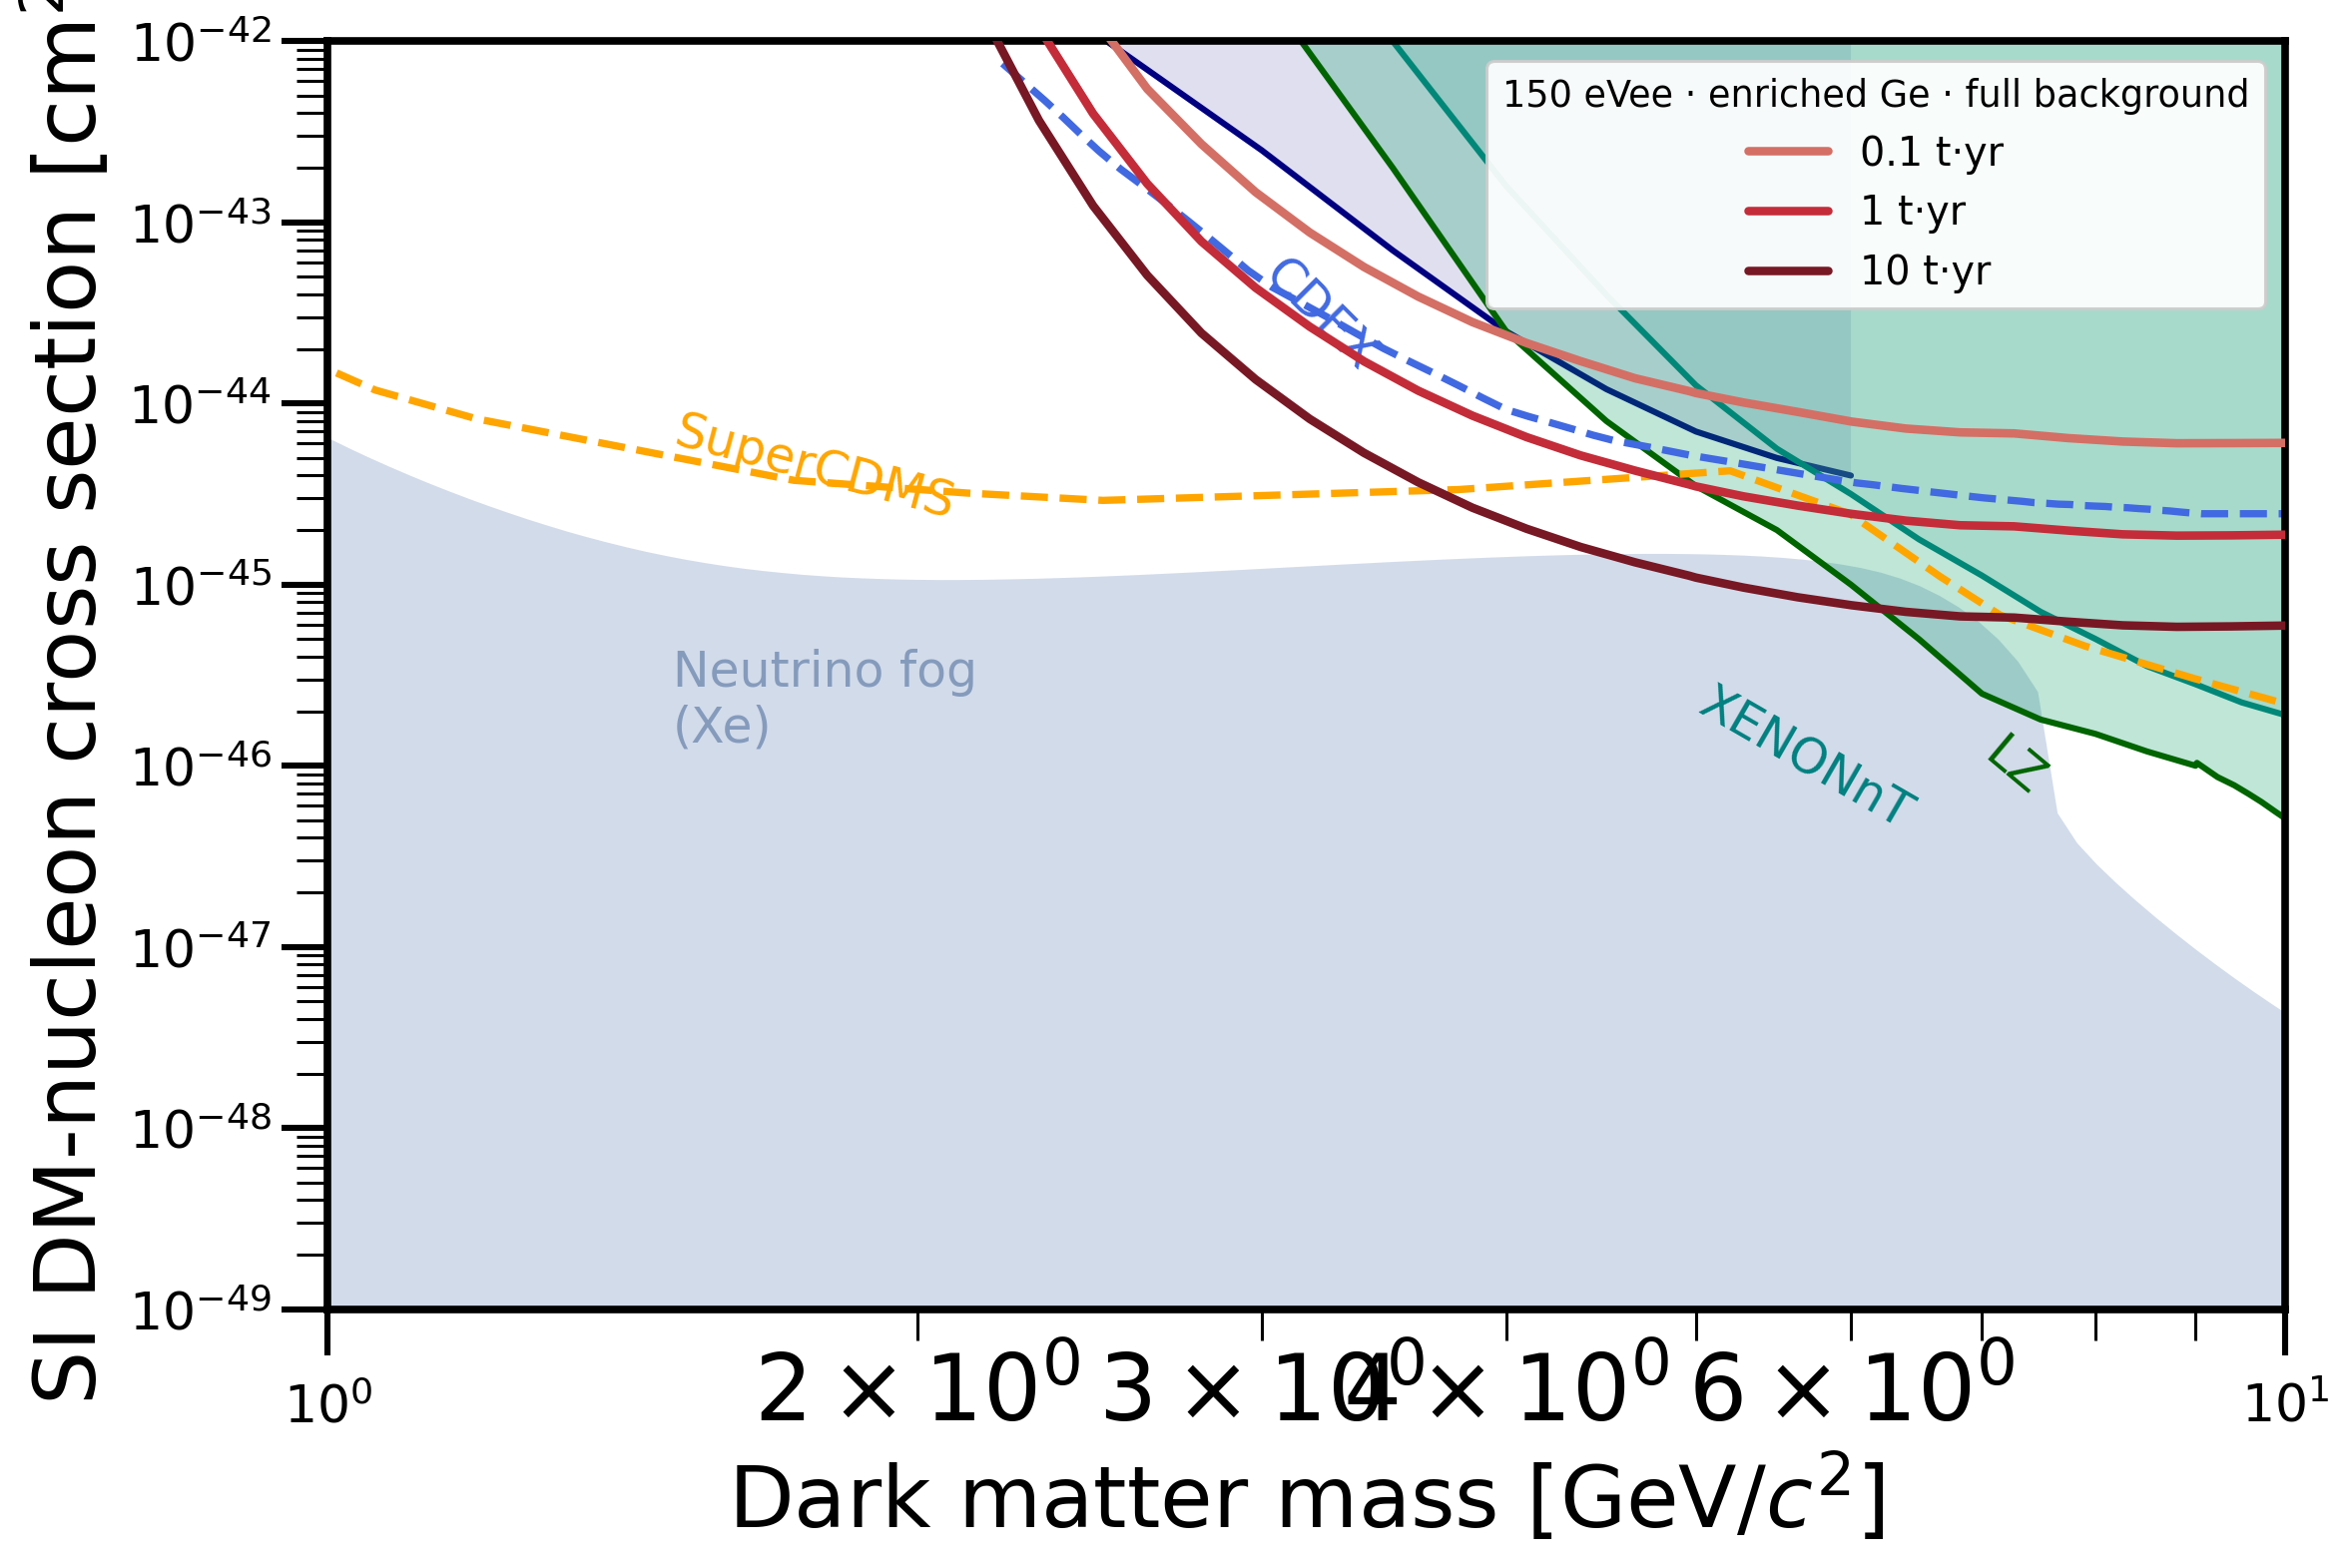

In [8]:
from IPython.display import display, Image
for name in ('01_energy_spectra','02_neutrino_best_case',
             '03_background_comparison','04_threshold_comparison',
             '05_exposure_comparison'):
    print(name)
    display(Image(filename=str(FIGURE_DIR/(name+'.png')),width=900))
